In [1]:
# 6.5 配送效率与用户评分可视化
# 6.5.1 数据读取与完整性核验

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 项目路径
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

data_dir = project_root / "data/processed"
fig_dir = project_root / "reports/figures"
fig_dir.mkdir(parents=True, exist_ok=True)

# 读取地区配送及用户评分数据
state_df = pd.read_csv(
    data_dir / "delivery_state_summary.csv",
    encoding="utf-8-sig"
)

review_df = pd.read_csv(
    data_dir / "delivery_review_by_delay.csv",
    encoding="utf-8-sig"
)

# 核验订单数及数据完整性
assert len(state_df) == 27
assert len(review_df) == 6

assert state_df["total_orders"].sum() == 96203
assert state_df["delayed_orders"].sum() == 6531

assert review_df["total_orders"].sum() == 96203
assert review_df["reviewed_orders"].sum() == 95560

# 设置延迟等级顺序
delay_order = [
    "On-time",
    "1-3 days",
    "4-7 days",
    "8-14 days",
    "15-30 days",
    "31+ days"
]

review_df["delay_group"] = pd.Categorical(
    review_df["delay_group"],
    categories=delay_order,
    ordered=True
)

review_df = review_df.sort_values("delay_group")

print("State data:", state_df.shape)
print("Review data:", review_df.shape)

State data: (27, 8)
Review data: (6, 7)


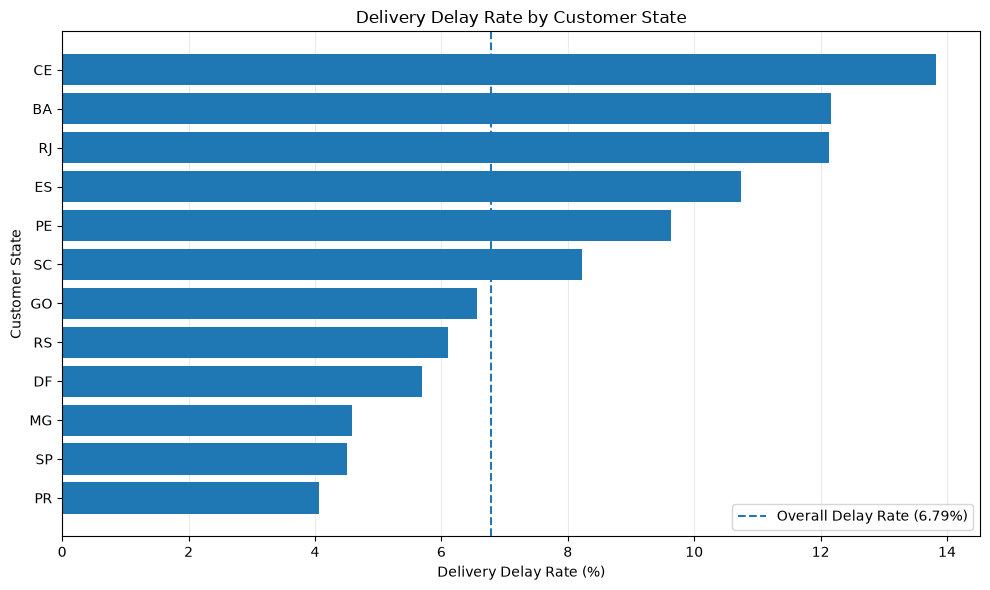

In [2]:
# 6.5.2 主要买家州的配送延迟率
# 仅展示有效配送订单不少于 1000 的地区，减少小样本干扰。

plot_df = (
    state_df[state_df["total_orders"] >= 1000]
    .sort_values("delay_rate_pct")
)

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    plot_df["customer_state"],
    plot_df["delay_rate_pct"]
)

# 平台整体延迟率作为参考线
ax.axvline(
    6.79,
    linestyle="--",
    label="Overall Delay Rate (6.79%)"
)

ax.set_xlabel("Delivery Delay Rate (%)")
ax.set_ylabel("Customer State")
ax.set_title("Delivery Delay Rate by Customer State")

ax.legend()
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    fig_dir / "state_delivery_delay_rate.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

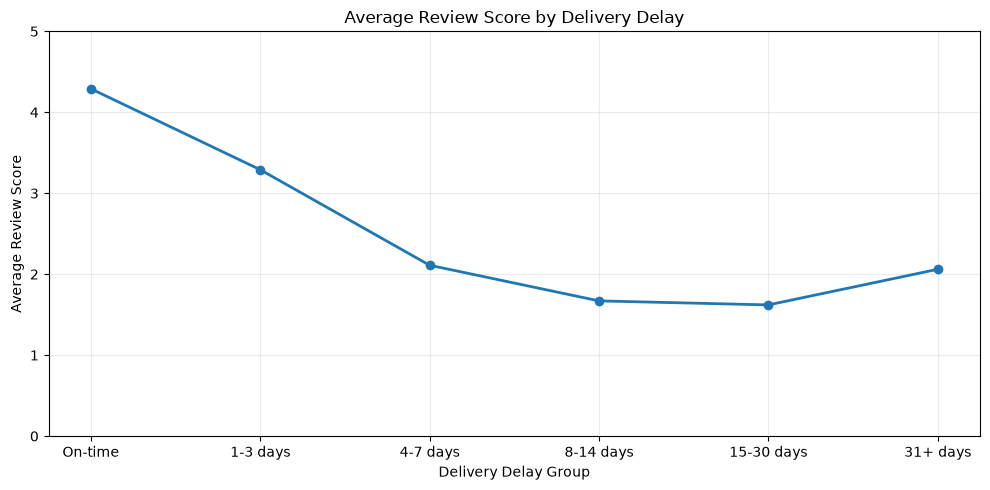

In [3]:
# 6.5.3 不同延迟程度的用户平均评分
# 以订单为单位计算平均评分，仅包含有评价的订单。

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    review_df["delay_group"].astype(str),
    review_df["avg_review_score"],
    marker="o",
    linewidth=2
)

ax.set_xlabel("Delivery Delay Group")
ax.set_ylabel("Average Review Score")
ax.set_title("Average Review Score by Delivery Delay")

ax.set_ylim(0, 5)
ax.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    fig_dir / "delay_review_score.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

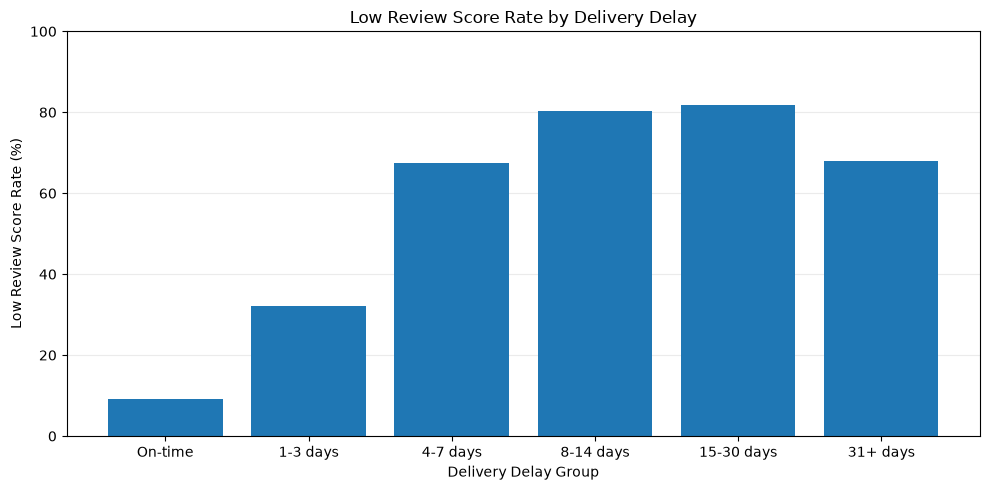

In [4]:
# 6.5.4 不同延迟程度的低评分订单占比
# 低评分定义：订单平均评分小于 3 分。
# 分母为对应延迟等级中有评价的订单数。

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    review_df["delay_group"].astype(str),
    review_df["low_score_rate_pct"]
)

ax.set_xlabel("Delivery Delay Group")
ax.set_ylabel("Low Review Score Rate (%)")
ax.set_title("Low Review Score Rate by Delivery Delay")

ax.set_ylim(0, 100)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    fig_dir / "delay_low_score_rate.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()